In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
def T_adiabatic(z, Tsfc, Gamma):

    if np.isscalar(z):
        T = Tsfc
    else:
        T = np.zeros(len(z))
        for i in range(len(z)):
            T[i] = Tsfc - Gamma * z[i]
    return T

def p_analytical(z, Tsfc, g = 9.81, Rd = 287.05, gamma = -0.006, p0 = 101800):

    T = T_adiabatic(z, Tsfc, Gamma)

    p = p0 * (1 + (gamma * z) / Tsfc) ** (-(g) / (Rd * gamma))

    return p

def q(p,e, Rd = 287.05, Rv = 461.50):

    return e / ((Rv / Rd) * (p - e) + e)

def esat(T):

    return 610.78 * np.exp((17.2694 * (T - 273.16)) / (T - 35.86))

def vapor_q(p, z, RH, Tsfc, gamma, Rd = 287.05, Rv = 461.50):

    T = T_adiabatic(z, Tsfc, gamma)

    e_sat = esat(T)

    e_vap = RH * e_sat

    q_vap = q(p, e_vap)

    q_vap = q_vap * 1000 # convert to g/kg

    return q_vap

def qsat(p, z, Tsfc, gamma, Rd = 287.05, Rv = 461.50):

    T = T_adiabatic(z, Tsfc, gamma)

    e_sat = esat(T)

    q_sat = q(p,e_sat)

    return q_sat


q_v = 20.99 g/kg
Cloud base height = 487.00m


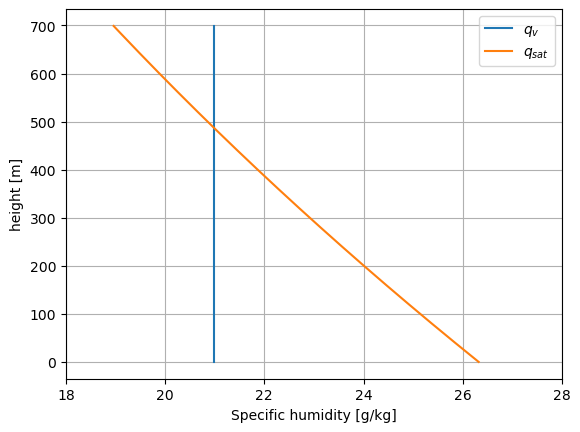

In [11]:
# Variables
Tsfc = 30 + 273.15 #K
RHsfc = 0.8
Psfc = 101800 #pa
Gamma = 0.0098 # K/m

z = np.arange(0, 700, 1)

# q_v calculation
q_v = vapor_q(Psfc, 0, RHsfc, Tsfc, Gamma)
print(f'q_v = {q_v:.2f} g/kg')
q_v = (q_v) * np.ones(len(z))

# q_sat calculation
p = p_analytical(z, Tsfc = Tsfc, p0 = Psfc, gamma = -Gamma)
q_sat = qsat(p, z, Tsfc, Gamma)
q_sat *= 1000

# Cloud base height
idx = np.argmax(q_sat < q_v)  
print(f'Cloud base height = {idx:.2f}m')


# Plotting
plt.plot(q_v, z, label ='$q_v$')
plt.plot(q_sat, z, label = '$q_{sat}$')
plt.ylabel('height [m]')
plt.xlabel('Specific humidity [g/kg]')
plt.legend()
plt.xlim([18,28])
plt.grid()
plt.savefig('./Figures/q_v_q_sat.png', dpi=300)
plt.show()

